# Лабораторная работа 2. Логистическая и линейная регрессия

В Ames линейная комбинация свойств дома определяет логит принадлежности к классу отдельно стоящих односемейных домов. Для аукциона линейная модель напрямую оценивает длительность проверки в секундах. Масштабы числовых признаков согласованы, что особенно важно при штрафе на величину коэффициентов.

Во всех работах используются одни и те же объекты. Для Ames это 2 344 дома в обучении и 586 в тесте. Определяем принадлежность к классу отдельно стоящих односемейных домов (1 — `1Fam`, 0 — остальные типы). Для Auction Verification это 1 723 запроса в обучении и 320 в тесте. Прогнозируем длительность проверки в секундах на пяти конфигурациях лимитов участников, отсутствующих в обучении. [Постановка задач, источники и разведочный анализ](01_knn.ipynb)

## Данные и разбиение выборки

In [1]:
# Указываем входные признаки и параметры эксперимента.
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SEED = 42
AMES_NUM = [
    "Lot Area", "Lot Frontage", "Year Built", "Overall Qual", "Overall Cond",
    "Gr Liv Area", "1st Flr SF", "2nd Flr SF", "Total Bsmt SF", "Full Bath",
    "Half Bath", "Bedroom AbvGr", "Kitchen AbvGr", "TotRms AbvGrd",
    "Garage Area", "Garage Cars",
]
AMES_CAT = ["Neighborhood", "House Style", "Foundation", "Roof Style"]
CAPACITIES = [f"process.b{i}.capacity" for i in range(1, 5)]
AUCTION_CAT = ["property.product", "property.winner"]
AUCTION_FEATURES = [*CAPACITIES, "property.price", *AUCTION_CAT]
RUNTIME = "verification.time"
TASKS = ("classification", "regression")
TASK_NAME = {"classification": "Классификация", "regression": "Регрессия"}



LAB = 2
ALGORITHM = "Линейные модели"

In [2]:
# Читаем данные и формируем обучающие, проверочные и тестовые выборки.
@dataclass
class Sample:
    X: pd.DataFrame
    y: np.ndarray
    identifiers: np.ndarray
    train: np.ndarray
    test: np.ndarray
    folds: list
    groups: np.ndarray | None = None


def load_samples():
    """Индексы train/test и индексы фолдов относятся к строкам исходной таблицы."""
    ames = pd.read_csv(ROOT / "data/AmesHousing.csv")
    auction = pd.read_csv(ROOT / "data/auction_verification.csv")
    if not ames["PID"].is_unique:
        raise ValueError("Ожидались уникальные идентификаторы объектов")
    if ames["Bldg Type"].isna().any() or auction[RUNTIME].isna().any():
        raise ValueError("В исходной разметке есть пропуски")
    y = ames["Bldg Type"].eq("1Fam").astype(int).to_numpy()
    X = ames[AMES_NUM + AMES_CAT].copy()
    train, test = train_test_split(
        np.arange(len(y)), test_size=0.2, stratify=y, random_state=SEED,
    )
    splits = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    folds = [(train[a], train[b]) for a, b in splits.split(X.iloc[train], y[train])]
    classification = Sample(X, y, ames["PID"].to_numpy(), train, test, folds)

    # Лимиты четырёх участников задают конфигурацию одной модели аукциона.
    X = auction[AUCTION_FEATURES].copy()
    X[AUCTION_CAT] = X[AUCTION_CAT].astype(str)
    y = auction[RUNTIME].to_numpy(dtype=float) / 1000  # из миллисекунд в секунды
    groups = auction.groupby(CAPACITIES, sort=True).ngroup().to_numpy()
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
    train, test = next(splitter.split(X, y, groups))
    splits = GroupKFold(n_splits=3, shuffle=True, random_state=SEED)
    folds = [(train[a], train[b]) for a, b in splits.split(X.iloc[train], y[train], groups[train])]
    for a, b in [(train, test), *folds]:
        assert not set(groups[a]) & set(groups[b])
    regression = Sample(X, y, np.arange(1, len(auction) + 1), train, test, folds, groups)
    return {"classification": classification, "regression": regression}



samples = load_samples()

In [3]:
# Формируем признаки и обучаем преобразования внутри каждого разбиения.
def feature_frame(X, task, mode):
    """Построчные преобразования используют только поля конкретного объекта."""
    if mode == "base":
        return X
    if mode != "extra":
        raise ValueError(f"Неизвестный набор признаков {mode}")
    result = X.copy()
    if task == "classification":
        lot = X["Lot Area"].replace(0, np.nan)
        above_ground = X["Gr Liv Area"].replace(0, np.nan)
        result["Жилая площадь / участок"] = X["Gr Liv Area"] / lot
        result["Гараж / жилая площадь"] = X["Garage Area"] / above_ground
    else:
        result["Сумма лимитов"] = X[CAPACITIES].sum(axis=1)
        result["Произведение по лимитам"] = (X[CAPACITIES] + 1).prod(axis=1)
    return result


def design(sample, task, mode, train, evaluate):
    """Обучаем заполнение пропусков, шкалу и словарь категорий внутри каждого разбиения."""
    frame = feature_frame(sample.X, task, mode)
    cats = AMES_CAT if task == "classification" else AUCTION_CAT
    nums = [column for column in frame.columns if column not in cats]
    transformers = [("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), nums)]
    if cats:
        encoder = make_pipeline(
            SimpleImputer(strategy="constant", fill_value="(пропуск)"),
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        )
        transformers.append(("cat", encoder, cats))
    transform = ColumnTransformer(transformers)
    return transform.fit_transform(frame.iloc[train]), transform.transform(frame.iloc[evaluate])

## Метрики и правила сравнения

В Ames основной показатель — **macro-F1**. Для каждого класса вычисляем гармоническое среднее точности и полноты, затем усредняем два результата с равными весами. Дополнительно приводим **accuracy** (долю верных ответов) и **balanced accuracy** (среднюю полноту классов).

Также рассчитываем **ROC-AUC** по вероятностям класса `1Fam`. Он показывает, насколько хорошо модель ранжирует два класса при разных порогах. Чем ближе ROC-AUC к 1, тем лучше.

В UCI минимизируем **MAE** — среднюю абсолютную ошибку длительности проверки в секундах. **RMSE** сильнее штрафует крупные ошибки. **R²** показывает, насколько хорошо прогнозы объясняют вариацию времени относительно константы, равной среднему значению тестовых целей. У R² возможны и отрицательные значения.

Для подбора используем **три фолда внутри обучения**. В Ames сохраняем доли классов; в UCI все запросы с одинаковыми четырьмя лимитами участников остаются вместе. Сравниваем средние значения macro-F1 и MAE по фолдам. При равенстве с точностью до 10⁻¹² остаётся первая из перечисленных конфигураций. После выбора переобучаем модель на всей обучающей части. Библиотечная и собственная версии получают одинаковые матрицы признаков в каждом режиме.

## Бейзлайн и гипотезы

Для Ames проверим, повышают ли macro-F1 балансировка классов и усиление L2-регуляризации (уменьшение C с 1 до 0,1). Для прогноза длительности оценим, снизит ли MAE регуляризация Ridge. Отдельно проверим производные признаки на обеих задачах, затем совместим их с изменениями модели. Сумма лимитов уже выражается линейной комбинацией входных признаков. Произведение четырёх величин (1 + лимит) добавляет взаимодействия между участниками.

Метка `base` означает исходные признаки. Числовые пропуски заполняются медианой, числовые признаки стандартизуются, категории кодируются индикаторами. Все параметры преобразований оцениваются на обучающей части соответствующего фолда. В режиме `extra` для Ames добавляются отношения жилой площади к площади участка и площади гаража к жилой площади, для аукциона — сумма четырёх лимитов и произведение их увеличенных на единицу значений. Произведение служит приближённым индикатором числа возможных комбинаций загрузки участников.

In [4]:
# Задаём семейство моделей и конфигурации до оценки на тесте.
from scipy.optimize import minimize
from scipy.special import expit
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge

def candidates(task):
    if task == "classification":
        return [
            {"name": "Логистическая, C=1", "features": "base",
             "params": {"C": 1.0, "class_weight": None}},
            {"name": "Балансировка классов", "features": "base",
             "params": {"C": 1.0, "class_weight": "balanced"}},
            {"name": "Усиленный штраф, C=0,1", "features": "base",
             "params": {"C": 0.1, "class_weight": None}},
            {"name": "Производные признаки", "features": "extra",
             "params": {"C": 1.0, "class_weight": None}},
            {"name": "Балансировка, штраф и признаки", "features": "extra",
             "params": {"C": 0.1, "class_weight": "balanced"}},
        ]
    return [
        {"name": "Обычный МНК", "features": "base", "params": {"alpha": 0.0}},
        {"name": "Ridge, α=1", "features": "base", "params": {"alpha": 1.0}},
        {"name": "Ridge, α=10", "features": "base", "params": {"alpha": 10.0}},
        {"name": "Производные признаки", "features": "extra", "params": {"alpha": 0.0}},
        {"name": "Ridge, α=1 и признаки", "features": "extra", "params": {"alpha": 1.0}},
    ]

def make_model(task, own, params):
    if task == "classification":
        if own:
            return BinaryLogisticRegression(**params)
        return LogisticRegression(max_iter=2500, solver="lbfgs", tol=1e-7, **params)
    if own:
        return LeastSquaresRegression(**params)
    return Ridge(**params) if params["alpha"] > 0 else LinearRegression()

### Проверка гипотез на обучающих фолдах

В таблицах показаны индивидуальные оценки, среднее, выборочное стандартное отклонение и разность средних относительно базовой строки. Положительная разность полезна для macro-F1, отрицательная — для MAE.

In [5]:
# Задаём основные и дополнительные метрики.
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score, f1_score,
    mean_absolute_error, r2_score, root_mean_squared_error, roc_auc_score,
)



PRIMARY = {"classification": "macro_f1", "regression": "mae"}
NAMES = {"macro_f1": "macro-F1", "mae": "MAE", "balanced_accuracy": "Balanced accuracy",
         "accuracy": "Accuracy", "roc_auc": "ROC-AUC", "rmse": "RMSE", "r2": "R²"}
IMPLEMENTATION = {"sklearn": "sklearn", "own": "Самостоятельная"}
STAGE = {"base": "Базовая", "selected": "Выбор по CV"}


def scores(task, y, prediction):
    if task == "classification":
        return {
            "macro_f1": f1_score(y, prediction, average="macro", zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(y, prediction),
            "accuracy": accuracy_score(y, prediction),
        }
    return {"mae": mean_absolute_error(y, prediction),
            "rmse": root_mean_squared_error(y, prediction), "r2": r2_score(y, prediction)}

In [6]:
# Сравниваем конфигурации на трёх фолдах и выводим результаты.
def tune(samples, candidates, make_model, lab, algorithm):
    """CV только на обучающей выборке. При равенстве остаётся первый кандидат."""
    rows, chosen = [], {}
    for task in TASKS:
        sample = samples[task]
        options = candidates(task)
        matrices = {}
        task_rows = []
        for i, option in enumerate(options):
            mode = option["features"]
            if mode not in matrices:
                matrices[mode] = [design(sample, task, mode, a, b) for a, b in sample.folds]
            values = []
            for (a, b), (X_train, X_valid) in zip(sample.folds, matrices[mode]):
                model = make_model(task, False, option["params"]).fit(X_train, sample.y[a])
                prediction = model.predict(X_valid)
                values.append(scores(task, sample.y[b], prediction)[PRIMARY[task]])
            task_rows.append({
                "lab": lab, "algorithm": algorithm, "task": task,
                "configuration": option["name"], "features": mode,
                "params": json.dumps(option["params"], ensure_ascii=False, sort_keys=True),
                **{f"fold_{j}": value for j, value in enumerate(values, 1)},
                "mean": np.mean(values), "std": np.std(values, ddof=1),
                "selected": False, "base": i == 0,
            })
        means = np.array([row["mean"] for row in task_rows])
        best = max(means) if task == "classification" else min(means)
        idx = int(np.flatnonzero(np.isclose(means, best, atol=1e-12, rtol=0))[0])
        task_rows[idx]["selected"] = True
        chosen[task] = options[idx]
        rows.extend(task_rows)
    return pd.DataFrame(rows), chosen


def show_cv(frame):
    for task in TASKS:
        sub = frame[frame.task.eq(task)].copy()
        primary = NAMES[PRIMARY[task]]
        base = sub.loc[sub.base, "mean"].iloc[0]
        sub["delta"] = sub["mean"] - base
        header = f"{TASK_NAME[task]} · {primary} " + ("↑" if task == "classification" else "↓")
        display(Markdown(f"**{header}**"))
        table = sub[["configuration", "features", "fold_1", "fold_2", "fold_3",
                     "mean", "std", "delta", "selected"]].copy()
        table["selected"] = table["selected"].map({True: "✓", False: ""})
        table.columns = ["Конфигурация", "Признаки", "Фолд 1", "Фолд 2", "Фолд 3",
                         "Среднее", "SD", "Δ к базе", "Выбор"]
        display(table.set_index("Конфигурация").round(4))
        winner = sub[sub.selected].iloc[0]
        print(f"Выбор по среднему значению: {winner.configuration} ({primary} {winner['mean']:.4f}).")

In [7]:
# Отбираем конфигурации только по CV, затем фиксируем выбор для обеих реализаций.
base = {task: candidates(task)[0] for task in TASKS}
cv, selected = tune(samples, candidates, make_model, LAB, ALGORITHM)
show_cv(cv)

**Классификация · macro-F1 ↑**

,Признаки,Фолд 1,Фолд 2,Фолд 3,Среднее,SD,Δ к базе,Выбор
Конфигурация,,,,,,,,
"Логистическая, C=1",base,0.9303,0.9312,0.9164,0.9259,0.0083,0.0000,
Балансировка классов,base,0.9269,0.8851,0.8958,0.9026,0.0217,-0.0234,
"Усиленный штраф, C=0,1",base,0.9114,0.9196,0.9086,0.9132,0.0057,-0.0127,
Производные признаки,extra,0.9458,0.9307,0.9147,0.9304,0.0155,0.0045,
"Балансировка, штраф и признаки",extra,0.9425,0.9223,0.9304,0.9317,0.0101,0.0058,✓


Выбор по среднему значению: Балансировка, штраф и признаки (macro-F1 0.9317).


**Регрессия · MAE ↓**

,Признаки,Фолд 1,Фолд 2,Фолд 3,Среднее,SD,Δ к базе,Выбор
Конфигурация,,,,,,,,
Обычный МНК,base,5.7624,5.2636,4.8858,5.3039,0.4396,0.0000,
"Ridge, α=1",base,5.7497,5.2628,4.8800,5.2975,0.4359,-0.0064,
"Ridge, α=10",base,5.6487,5.2752,4.8366,5.2535,0.4065,-0.0504,✓
Производные признаки,extra,5.7426,5.5366,4.8504,5.3766,0.4672,0.0726,
"Ridge, α=1 и признаки",extra,5.7302,5.5163,4.8478,5.3647,0.4603,0.0608,


Выбор по среднему значению: Ridge, α=10 (MAE 5.2535).


## Библиотечная модель на отложенной выборке

Сначала оцениваем базовую модель sklearn, затем модель с конфигурацией, выбранной по CV.

In [8]:
# Считаем и выводим метрики тестовых прогнозов.
def run_test(samples, configurations, make_model, lab, algorithm, implementation, stage):
    records, predictions = [], {}
    for task in TASKS:
        sample, config = samples[task], configurations[task]
        X_train, X_test = design(sample, task, config["features"], sample.train, sample.test)
        model = make_model(task, implementation == "own", config["params"])
        model.fit(X_train, sample.y[sample.train])
        pred = model.predict(X_test)
        auc = {}
        if task == "classification":
            # ROC-AUC оценивает ранжирование по вероятности положительного класса.
            probability = model.predict_proba(X_test)[:, 1]
            auc["roc_auc"] = roc_auc_score(sample.y[sample.test], probability)
        predictions[task] = pred
        records.append({
            "lab": lab, "algorithm": algorithm, "task": task, "implementation": implementation,
            "stage": stage, "configuration": config["name"],
            **scores(task, sample.y[sample.test], pred), **auc,
        })
    return pd.DataFrame(records), predictions


def show_test(results):
    for task in TASKS:
        cols = ["accuracy", "macro_f1", "roc_auc", "balanced_accuracy"] if task == "classification" else ["mae", "rmse", "r2"]
        tab = results.loc[results.task.eq(task), ["implementation", "stage", "configuration", *cols]].copy()
        tab["implementation"] = tab["implementation"].map(IMPLEMENTATION)
        tab["stage"] = tab["stage"].map(STAGE)
        tab = tab.rename(columns={"implementation": "Реализация", "stage": "Режим",
                                  "configuration": "Конфигурация", **NAMES})
        display(Markdown(f"**{TASK_NAME[task]}**"))
        display(tab.set_index(["Реализация", "Режим"]).round(4))

In [9]:
# Обучаем два библиотечных варианта на полном train и сравниваем на одном тесте.
lib_base, _ = run_test(samples, base, make_model, LAB, ALGORITHM, "sklearn", "base")
lib_selected, lib_pred = run_test(samples, selected, make_model, LAB, ALGORITHM, "sklearn", "selected")
show_test(pd.concat([lib_base, lib_selected], ignore_index=True))

**Классификация**

Конфигурация  Accuracy  macro-F1  \
Реализация Режим                                                             
sklearn    Базовая                  Логистическая, C=1    0.9556    0.9162   
           Выбор по CV  Балансировка, штраф и признаки    0.9608    0.9325   

                        ROC-AUC  Balanced accuracy  
Реализация Режим                                    
sklearn    Базовая       0.9409              0.887  
           Выбор по CV   0.9523              0.941

**Регрессия**

Конфигурация     MAE    RMSE      R²
Реализация Режим                                           
sklearn    Базовая      Обычный МНК  4.8843  6.2889  0.5430
           Выбор по CV  Ridge, α=10  4.8041  6.2247  0.5523

## Самостоятельная реализация

В классификаторе минимизируем сумму логистических потерь и квадратичного штрафа ‖w‖²/(2C). Градиент по коэффициентам и свободному члену вычислен аналитически и передаётся универсальному оптимизатору L-BFGS-B из SciPy. При балансировке вес объекта равен n/(2nₖ), где nₖ — число обучающих объектов его класса. Для регрессии центрируем признаки и цель, затем решаем задачу наименьших квадратов. При α > 0 добавляем к матрице строку для каждого коэффициента с элементом √α на диагонали и нулевой целью. Это реализует штраф Ridge, сохраняя свободный член без штрафа.

In [10]:
# Реализуем обучение и прогноз по формулам алгоритма.
class BinaryLogisticRegression:
    """Минимизация логистических потерь с аналитически заданным градиентом."""

    def __init__(self, C=1.0, class_weight=None):
        self.C = C
        self.class_weight = class_weight

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        self.classes_, encoded = np.unique(y, return_inverse=True)
        if len(self.classes_) != 2 or self.C <= 0:
            raise ValueError("Нужны два класса и положительный C")
        sample_weight = np.ones(len(encoded))
        if self.class_weight == "balanced":
            counts = np.bincount(encoded)
            sample_weight = len(encoded) / (2 * counts[encoded])
        elif self.class_weight is not None:
            raise ValueError("Поддерживаются class_weight=None и 'balanced'")
        weight_sum = sample_weight.sum()

        def loss_and_gradient(parameters):
            coef, intercept = parameters[:-1], parameters[-1]
            logits = X @ coef + intercept
            # logaddexp и expit устойчивы при больших логитах.
            losses = np.logaddexp(0.0, logits) - encoded * logits
            loss = sample_weight @ losses + 0.5 / self.C * (coef @ coef)
            residual = sample_weight * (expit(logits) - encoded)
            grad = np.r_[X.T @ residual + coef / self.C, residual.sum()]
            return loss / weight_sum, grad / weight_sum

        result = minimize(loss_and_gradient, np.zeros(X.shape[1] + 1),
                          jac=True, method="L-BFGS-B",
                          options={"maxiter": 2500, "ftol": 1e-13, "gtol": 1e-7})
        if not result.success:
            raise RuntimeError(f"Оптимизация не сошлась: {result.message}")
        self.coef_, self.intercept_ = result.x[:-1], result.x[-1]
        return self

    def predict(self, X):
        score = np.asarray(X, dtype=float) @ self.coef_ + self.intercept_
        return self.classes_[(score > 0).astype(int)]


    def predict_proba(self, X):
        """Преобразуем линейный ответ в вероятность класса сигмоидой."""
        logits = np.asarray(X, dtype=float) @ self.coef_ + self.intercept_
        positive = expit(logits)
        return np.column_stack((1 - positive, positive))


class LeastSquaresRegression:
    """Обычный или регуляризованный МНК со свободным коэффициентом."""

    def __init__(self, alpha=0.0):
        self.alpha = alpha

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        if self.alpha < 0:
            raise ValueError("Штраф должен быть неотрицательным")
        mean_x, mean_y = X.mean(axis=0), y.mean()
        matrix, target = X - mean_x, y - mean_y
        if self.alpha:
            # Дополнительные строки задают L2-штраф только для коэффициентов.
            penalty = np.sqrt(self.alpha) * np.eye(X.shape[1])
            matrix = np.vstack([matrix, penalty])
            target = np.r_[target, np.zeros(X.shape[1])]
        self.coef_ = np.linalg.lstsq(matrix, target, rcond=None)[0]
        self.intercept_ = mean_y - mean_x @ self.coef_
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.coef_ + self.intercept_

Переносим в собственную модель те же признаки и гиперпараметры. Базовую версию сопоставляем с исходным sklearn, а версию после подбора — с библиотечной при той же настройке.

In [11]:
# Оцениваем собственные модели в двух режимах и сравниваем все четыре варианта.
own_base, _ = run_test(samples, base, make_model, LAB, ALGORITHM, "own", "base")
own_selected, own_pred = run_test(samples, selected, make_model, LAB, ALGORITHM, "own", "selected")
results = pd.concat([lib_base, lib_selected, own_base, own_selected], ignore_index=True)
show_test(results)

**Классификация**

Конфигурация  Accuracy  \
Реализация      Режим                                                   
sklearn         Базовая                  Логистическая, C=1    0.9556   
                Выбор по CV  Балансировка, штраф и признаки    0.9608   
Самостоятельная Базовая                  Логистическая, C=1    0.9556   
                Выбор по CV  Балансировка, штраф и признаки    0.9608   

                             macro-F1  ROC-AUC  Balanced accuracy  
Реализация      Режим                                              
sklearn         Базовая        0.9162   0.9409              0.887  
                Выбор по CV    0.9325   0.9523              0.941  
Самостоятельная Базовая        0.9162   0.9409              0.887  
                Выбор по CV    0.9325   0.9523              0.941

**Регрессия**

Конфигурация     MAE    RMSE      R²
Реализация      Режим                                           
sklearn         Базовая      Обычный МНК  4.8843  6.2889  0.5430
                Выбор по CV  Ridge, α=10  4.8041  6.2247  0.5523
Самостоятельная Базовая      Обычный МНК  4.8843  6.2889  0.5430
                Выбор по CV  Ridge, α=10  4.8041  6.2247  0.5523

## Диагностика ошибок

Строки матрицы соответствуют фактическому типу здания, столбцы — прогнозу. На правом графике точки выше диагонали означают завышение времени, ниже — занижение. Обе панели показывают модель sklearn после подбора.

In [12]:
# Строим матрицу ошибок и сопоставляем прогноз времени с наблюдениями.
def plot_predictions(samples, predictions):
    """Ошибки выбранных библиотечных моделей на общем тесте."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
    s = samples["classification"]
    cm = ConfusionMatrixDisplay.from_predictions(
        s.y[s.test], predictions["classification"], display_labels=["Другие", "1Fam"],
        ax=axes[0], cmap="Blues", colorbar=False, values_format="d",
    )
    cm.ax_.set(title="Ошибки классификации", xlabel="Предсказанный класс", ylabel="Истинный класс")
    s = samples["regression"]
    y, pred = s.y[s.test], predictions["regression"]
    lo, hi = min(y.min(), pred.min()), max(y.max(), pred.max())
    axes[1].plot([lo, hi], [lo, hi], color="#576473", lw=1, ls="--", label="Точный прогноз")
    axes[1].scatter(y, pred, s=23, alpha=.68, color="#126d79", edgecolors="none")
    axes[1].set(title="Время формальной проверки", xlabel="Факт, с",
                ylabel="Прогноз, с", xlim=(lo - 1, hi + 1), ylim=(lo - 1, hi + 1))
    axes[1].legend(frameon=False, loc="upper left", fontsize=9)
    plt.show()

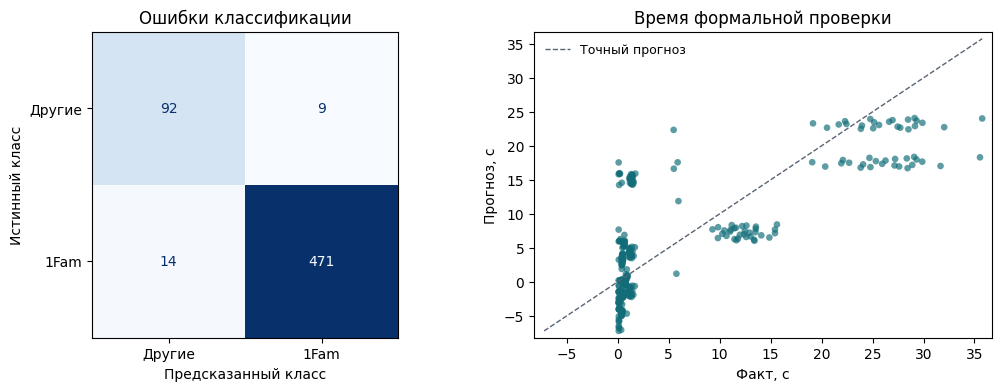

Другие типы, ошибочно отнесённые к 1Fam: 9 из 101.
Классовые прогнозы своей модели и sklearn расходятся на 0 из 586 домов.
Наибольшая абсолютная ошибка sklearn: 17.47 с (факт 0.08, прогноз 17.55, номер наблюдения = 9).


In [13]:
# Находим ошибки по классам, максимальную ошибку длительности и расхождение реализаций.
plot_predictions(samples, lib_pred)
sample = samples["classification"]
truth = sample.y[sample.test]
missed = ((truth == 0) & (lib_pred["classification"] == 1)).sum()
disagreements = np.sum(lib_pred["classification"] != own_pred["classification"])
print(f"Другие типы, ошибочно отнесённые к 1Fam: {missed} из {(truth == 0).sum()}.")
print(f"Классовые прогнозы своей модели и sklearn расходятся на {disagreements} из {len(truth)} домов.")
sample = samples["regression"]
truth = sample.y[sample.test]
pred = lib_pred["regression"]
idx = np.argmax(np.abs(pred - truth))
print(f"Наибольшая абсолютная ошибка sklearn: {abs(pred[idx] - truth[idx]):.2f} с "
      f"(факт {truth[idx]:.2f}, прогноз {pred[idx]:.2f}, номер наблюдения = {sample.identifiers[sample.test[idx]]}).")

## Выводы

In [14]:
# Сопоставляем реализации и сохраняем результаты в CSV.
def describe(results, cv):
    """Сравниваем стадии у каждой реализации и обе реализации при одинаковых настройках."""
    for task in TASKS:
        metric = PRIMARY[task]
        tab = results[results.task.eq(task)].pivot(index="implementation", columns="stage", values=metric)
        base, selected = tab.loc["sklearn", ["base", "selected"]]
        scratch_base, scratch_selected = tab.loc["own", ["base", "selected"]]
        direction = 1 if task == "classification" else -1
        delta = selected - base
        verdict = "улучшился" if direction * delta > 1e-9 else "ухудшился" if direction * delta < -1e-9 else "не изменился"
        vals = cv[cv.task.eq(task)]
        name = vals.loc[vals.selected, "configuration"].iloc[0]
        text = (f"**{TASK_NAME[task]}.** По CV выбрана конфигурация «{name}». "
                f"На тесте показатель {NAMES[metric]} у sklearn {verdict}: "
                f"{base:.4f} → {selected:.4f}. У собственной реализации: "
                f"{scratch_base:.4f} → {scratch_selected:.4f}. ")
        diff_base, diff_selected = scratch_base - base, scratch_selected - selected
        if max(abs(diff_base), abs(diff_selected)) < 1e-9:
            text += "По этой метрике результаты двух реализаций совпали в обоих режимах."
        else:
            text += (f"Разность «своя минус sklearn» составила {diff_base:+.4f} "
                     f"для базовой и {diff_selected:+.4f} для выбранной настройки.")
        display(Markdown(text))


def save_results(lab, results, cv):
    folder = ROOT / "results"
    folder.mkdir(exist_ok=True)
    results.to_csv(folder / f"lab_{lab}_metrics.csv", index=False)
    cv.to_csv(folder / f"lab_{lab}_cv.csv", index=False)

In [15]:
# Измеряем эффект подбора и сравниваем свои модели с библиотечными в обоих режимах.
describe(results, cv)
save_results(LAB, results, cv)

**Классификация.** По CV выбрана конфигурация «Балансировка, штраф и признаки». На тесте показатель macro-F1 у sklearn улучшился: 0.9162 → 0.9325. У собственной реализации: 0.9162 → 0.9325. По этой метрике результаты двух реализаций совпали в обоих режимах.

**Регрессия.** По CV выбрана конфигурация «Ridge, α=10». На тесте показатель MAE у sklearn улучшился: 4.8843 → 4.8041. У собственной реализации: 4.8843 → 4.8041. По этой метрике результаты двух реализаций совпали в обоих режимах.

В регрессии добавление агрегатов лимитов к обычному МНК подняло среднюю ошибку на фолдах с 5,304 до 5,377 с. Лучшей из проверенных линейных моделей оказалась Ridge с α = 10 и исходными признаками. У обычной линейной модели есть практическое ограничение: на 117 из 320 тестовых запросов она предсказала отрицательную длительность. Метрики в таблице рассчитаны по её исходным прогнозам.

[Сводное сравнение всех пяти алгоритмов](06_summary.ipynb)